In [1]:
%edit
%load_ext autoreload
%autoreload 2

IPython will make a temporary file named: /tmp/ipython_edit_cjkgyhub/ipython_edit_szij4lih.py


In [2]:
import sys
from pathlib import Path
from spacegraph_codebase.vi_utils import *

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [3]:
exp_dir = Path("experiments_1022")

In [4]:
import matplotlib
matplotlib.use('Agg')
%matplotlib inline

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
'''
Developed by Gengchen Mai

gengchen.mai@gmail.com
05/08/2019
'''


from argparse import ArgumentParser

from spacegraph_codebase.utils import *
from spacegraph_codebase.Place2Vec.cur_data_utils import load_pointset
from spacegraph_codebase.data_utils import load_ng
from spacegraph_codebase.model import NeighGraphEncoderDecoder
from spacegraph_codebase.train_helper import run_train, run_eval, run_joint_train

from torch import optim
import numpy as np

from spacegraph_codebase.trainer import make_args_parser, make_args_combine
parser = make_args_parser()

In [5]:
from pathlib import Path
import shlex
import pandas as pd

scripts_dir = Path(exp_dir / "scripts")
results_dir = Path(exp_dir / "results")

records = []

for sh_file in sorted(scripts_dir.glob("*.sh")):
    command = sh_file.read_text(encoding="utf-8")

    # 行末の \ による改行を結合
    command = command.replace("\\\n", " ")

    # コメント・空行を除外し、単語に分割
    tokens = shlex.split(command, comments=True)

    # trainモジュールの位置を探す
    module_name = "spacegraph_codebase.Place2Vec.train"

    if module_name not in tokens:
        print(f"SKIP: {sh_file.name}")
        continue

    start = tokens.index(module_name) + 1
    args_list = tokens[start:]

    args = parser.parse_args(args_list)
    args_com = make_args_combine(args)

    log_file = Path(results_dir) / f"{args_com.lstrip('/')}.log"
    
    record = vars(args).copy()
    record["script"] = sh_file.name
    record["args_com"] = args_com
    record["log_file"] = str(log_file)
    record["log_exists"] = log_file.exists()

    records.append(record)

df = pd.DataFrame(records)

print(f"実験数: {len(df)}")
print(f"ログあり: {df['log_exists'].sum()}")

display(df)

実験数: 61
ログあり: 61


,data_dir,model_dir,log_dir,num_context_sample,seed,embed_dim,dropout,enc_agg,model_type,num_rbf_anchor_pts,...,batch_size,tol,log_every,val_every,load_model,cuda,script,args_com,log_file,log_exists
0,./data_collection/Place2Vec_center/,./model_dir/Place2Vec_center/,./model_dir/Place2Vec_center/,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,False,Place2Vec_2_enc_dec_global_aodha.sh,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True
1,./data_collection/Place2Vec_center/,./model_dir/Place2Vec_center/,./model_dir/Place2Vec_center/,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,False,Place2Vec_2_enc_dec_global_grid.sh,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True
2,./data_collection/Place2Vec_center/,./model_dir/Place2Vec_center/,./model_dir/Place2Vec_center/,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,False,Place2Vec_2_enc_dec_global_gridlookup.sh,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True
3,./data_collection/Place2Vec_center/,./model_dir/Place2Vec_center/,./model_dir/Place2Vec_center/,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,False,Place2Vec_2_enc_dec_global_naive.sh,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True
4,./data_collection/Place2Vec_center/,./model_dir/Place2Vec_center/,./model_dir/Place2Vec_center/,10,0,64,0.5,mean,global,200,...,512,0.000001,50,50,False,False,Place2Vec_2_enc_dec_global_rbf.sh,/Place2Vec_center-0-10-64-0.5-mean-global-200-...,experiments_1022/results/Place2Vec_center-0-10...,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,./data_collection/Place2Vec_center/,././experiments_1022/results,././experiments_1022/results,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,True,wl_1022_sym4_scale_1000_stg_1_sigma_0.5_lambda...,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True
57,./data_collection/Place2Vec_center/,././experiments_1022/results,././experiments_1022/results,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,True,wl_1022_sym4_scale_500_stg_0_seed_0.sh,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True
58,./data_collection/Place2Vec_center/,././experiments_1022/results,././experiments_1022/results,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,True,wl_1022_sym4_scale_500_stg_1_sigma_0.5_lambda_...,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True
59,./data_collection/Place2Vec_center/,././experiments_1022/results,././experiments_1022/results,10,0,64,0.5,mean,global,0,...,512,0.000001,50,50,False,True,wl_1022_sym4_scale_500_stg_1_sigma_0.5_lambda_...,/Place2Vec_center-0-10-64-0.5-mean-global-0-10...,experiments_1022/results/Place2Vec_center-0-10...,True


In [6]:
import re
from pathlib import Path

def extract_test_metrics(log_file):
    text = Path(log_file).read_text(encoding="utf-8", errors="replace")

    pattern = (
        r"Iter:\s*(\d+);\s*(\d+)\s+Neg,\s*"
        r"Test MRR:\s*([\d.]+),\s*"
        r"HIT@1:\s*([\d.]+),\s*"
        r"HIT@5:\s*([\d.]+),\s*"
        r"HIT@10:\s*([\d.]+)"
    )

    matches = re.findall(pattern, text)

    result = {}

    for iteration, neg, mrr, hit1, hit5, hit10 in matches:
        result[f"test_mrr_{neg}neg"] = float(mrr)
        result[f"test_hit1_{neg}neg"] = float(hit1)
        result[f"test_hit5_{neg}neg"] = float(hit5)
        result[f"test_hit10_{neg}neg"] = float(hit10)
        result[f"test_iter_{neg}neg"] = int(iteration)

    return result

def extract_stg_metrics(log_file):
    text = Path(log_file).read_text(
        encoding="utf-8", errors="replace"
    )

    result = {}

    # STGの選択基底数・確率
    pattern_stg = (
        r"STG:\s*total=(\d+),\s*"
        r"selected\(p>0\.5\)=(\d+),\s*"
        r"expected_active=([-\d.]+),\s*"
        r"mean_prob=([-\d.]+)"
    )

    matches = re.findall(pattern_stg, text)

    if matches:
        total, selected, expected, mean_prob = matches[-1]

        result.update({
            "stg_total": int(total),
            "stg_selected": int(selected),
            "stg_expected_active": float(expected),
            "stg_mean_prob": float(mean_prob),
            "stg_selected_ratio": int(selected) / int(total),
        })

    # mu の統計情報
    pattern_mu = (
        r"mu_min\s*=\s*([-\d.]+),\s*"
        r"mu_max\s*=\s*([-\d.]+),\s*"
        r"mu_mean\s*=\s*([-\d.]+),\s*"
        r"\(mu<=0\)\.sum\(\)\s*=\s*(\d+)"
    )

    matches = re.findall(pattern_mu, text)

    if matches:
        mu_min, mu_max, mu_mean, mu_nonpositive = matches[-1]

        result.update({
            "mu_min": float(mu_min),
            "mu_max": float(mu_max),
            "mu_mean": float(mu_mean),
            "mu_nonpositive": int(mu_nonpositive),
        })

    return result

In [7]:
for i, row in df.iterrows():
    log_file = Path(row["log_file"])

    if not log_file.is_file():
        continue

    metrics = extract_test_metrics(log_file)

    for key, value in metrics.items():
        df.loc[i, key] = value

    metrics = extract_stg_metrics(log_file)

    for key, value in metrics.items():
        df.loc[i, key] = value

In [8]:
cols = [
    "script",
    "use_stg",
    "stg_lambda",
    "test_mrr_10neg",
    "test_hit1_10neg",
    "test_hit5_10neg",
    "test_hit10_10neg",
    "test_mrr_100neg",
    "test_hit1_100neg",
    "test_hit5_100neg",
    "test_hit10_100neg",
]

# display(df[cols])
df[cols]

,script,use_stg,stg_lambda,test_mrr_10neg,test_hit1_10neg,test_hit5_10neg,test_hit10_10neg,test_mrr_100neg,test_hit1_100neg,test_hit5_100neg,test_hit10_100neg
0,Place2Vec_2_enc_dec_global_aodha.sh,False,0.00,0.423934,0.223776,0.691841,0.973893,0.113342,0.037296,0.147319,0.255012
1,Place2Vec_2_enc_dec_global_grid.sh,False,0.00,0.467472,0.267599,0.745921,0.979953,0.130888,0.041492,0.186014,0.311888
2,Place2Vec_2_enc_dec_global_gridlookup.sh,False,0.00,0.448834,0.249417,0.719814,0.972028,0.119135,0.034499,0.174359,0.282517
3,Place2Vec_2_enc_dec_global_naive.sh,False,0.00,0.381142,0.179953,0.638695,0.961772,0.089911,0.022844,0.110956,0.215385
4,Place2Vec_2_enc_dec_global_rbf.sh,False,0.00,0.437952,0.228438,0.723077,0.974359,0.118229,0.038695,0.158974,0.273660
...,...,...,...,...,...,...,...,...,...,...,...
56,wl_1022_sym4_scale_1000_stg_1_sigma_0.5_lambda...,True,1.00,0.407432,0.207925,0.665734,0.967366,0.103023,0.032634,0.131469,0.241492
57,wl_1022_sym4_scale_500_stg_0_seed_0.sh,False,0.00,0.463189,0.257809,0.748718,0.966900,0.128194,0.040093,0.176690,0.307226
58,wl_1022_sym4_scale_500_stg_1_sigma_0.5_lambda_...,True,0.01,0.459016,0.248485,0.743590,0.968765,0.125714,0.037296,0.183683,0.297436
59,wl_1022_sym4_scale_500_stg_1_sigma_0.5_lambda_...,True,0.10,0.469364,0.260140,0.753380,0.972494,0.127943,0.041492,0.179953,0.308159


In [9]:
cols_stg = [
    "script",
    "stg_lambda",
    "test_mrr_100neg",
    "stg_total",
    "stg_selected",
    "stg_selected_ratio",
    "stg_expected_active",
    "stg_mean_prob",
    "mu_min",
    "mu_max",
    "mu_mean",
    "mu_nonpositive",
]

display(df[cols_stg])

,script,stg_lambda,test_mrr_100neg,stg_total,stg_selected,stg_selected_ratio,stg_expected_active,stg_mean_prob,mu_min,mu_max,mu_mean,mu_nonpositive
0,Place2Vec_2_enc_dec_global_aodha.sh,0.00,0.113342,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Place2Vec_2_enc_dec_global_grid.sh,0.00,0.130888,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Place2Vec_2_enc_dec_global_gridlookup.sh,0.00,0.119135,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Place2Vec_2_enc_dec_global_naive.sh,0.00,0.089911,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Place2Vec_2_enc_dec_global_rbf.sh,0.00,0.118229,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
56,wl_1022_sym4_scale_1000_stg_1_sigma_0.5_lambda...,1.00,0.103023,3021.0,142.0,0.047004,365.74,0.1211,-1.1116,1.1091,-0.7335,2879.0
57,wl_1022_sym4_scale_500_stg_0_seed_0.sh,0.00,0.128194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58,wl_1022_sym4_scale_500_stg_1_sigma_0.5_lambda_...,0.01,0.125714,12021.0,9941.0,0.826969,8598.34,0.7153,-1.0947,1.1008,0.2919,2080.0
59,wl_1022_sym4_scale_500_stg_1_sigma_0.5_lambda_...,0.10,0.127943,12021.0,7196.0,0.598619,6188.75,0.5148,-1.1065,1.0433,-0.0602,4825.0


In [10]:
df_path = Path(exp_dir) / "all_experiments_with_stg.csv"

df.to_csv(
    df_path,
    index=False,
    encoding="utf-8-sig"
)

In [11]:

def make_enc_dec(args):
    args_combine = make_args_combine(args)
    
    log_file = args.log_dir + args_combine + ".log"
    model_file = args.model_dir + args_combine + ".pth"

    logger = setup_logging(log_file, filemode='a')
    
    print("Loading PointSet data..")

    pointset, feature_embedding = load_pointset(data_dir=args.data_dir, 
                                                    embed_dim=args.embed_dim,
                                                    do_feature_sampling = False)
    if args.cuda:
        pointset.feature_embed_lookup = cudify(feature_embedding)
        
    # make feature encoder
    enc = get_encoder(pointset.feature_embed_lookup, feature_embedding, pointset, args.enc_agg)

    if args.model_type == "relative" or args.model_type == "join" or args.model_type == "together":
        # make relative space encoder
        spa_enc = get_spa_encoder(args=args,
                            model_type=args.model_type,
                            spa_enc_type=args.spa_enc,
                            pointset=None, 
                            spa_embed_dim=args.spa_embed_dim, 
                            coord_dim = 2, 
                            frequency_num = args.freq, 
                            max_radius = args.max_radius,
                            # dropout = args.dropout,
                            freq_init = args.freq_init)
    else:
        spa_enc = None

    if args.model_type == "global" or args.model_type == "join" or args.model_type == "together":
        # make global space encoder
        g_spa_enc = get_spa_encoder(args=args,
                            model_type=args.model_type,
                            spa_enc_type=args.g_spa_enc, 
                            spa_embed_dim=args.g_spa_embed_dim,
                            pointset=None, 
                            coord_dim = 2, 
                            frequency_num = args.g_freq, 
                            max_radius = args.g_max_radius,
                            # dropout = args.dropout,
                            freq_init = args.g_freq_init)
    else:
        g_spa_enc = None

    # make decoder
    if args.model_type == "relative" or args.model_type == "join" or args.model_type == "together":

        # make query embedding initial decoder
        init_dec = get_context_decoder(dec_type=args.init_decoder_atten_type, 
                            query_dim=args.embed_dim, 
                            key_dim=args.embed_dim, 
                            spa_embed_dim=args.spa_embed_dim, 
                            g_spa_embed_dim=args.g_spa_embed_dim,
                            have_query_embed = False, 
                            num_attn = args.init_decoder_atten_num, 
                            activation = args.init_decoder_atten_act, 
                            f_activation = args.init_decoder_atten_f_act, 
                            layn = args.init_decoder_use_layn, 
                            use_postmat = args.init_decoder_use_postmat,
                            dropout = args.dropout)

        if args.use_dec == "T":
            # make decoder
            dec = get_context_decoder(dec_type=args.decoder_atten_type, 
                                query_dim=args.embed_dim, 
                                key_dim=args.embed_dim, 
                                spa_embed_dim=args.spa_embed_dim, 
                                g_spa_embed_dim=args.g_spa_embed_dim,
                                have_query_embed = True, 
                                num_attn = args.decoder_atten_num, 
                                activation = args.decoder_atten_act, 
                                f_activation = args.decoder_atten_f_act, 
                                layn = args.decoder_use_layn, 
                                use_postmat = args.decoder_use_postmat,
                                dropout = args.dropout)
        else:
            dec = None

        if args.model_type == "join":
            joint_dec = JointRelativeGlobalDecoder(feature_embed_dim = args.embed_dim, 
                            f_act = args.act, 
                            dropout = args.dropout,
                            join_type = args.join_dec_type)
        else:
            joint_dec = None

    else:
        init_dec = None
        dec = None
        joint_dec = None

    if args.model_type == "global" or args.model_type == "join":
        # make global space decoder
        g_spa_dec = DirectPositionEmbeddingDecoder(g_spa_embed_dim=args.g_spa_embed_dim, 
                            feature_embed_dim=args.embed_dim, 
                            f_act = args.act, 
                            dropout = args.dropout)
    else:
        g_spa_dec = None




    # if args.model_type == "global" or args.model_type == "relative":
    # make encoder encoder
    enc_dec = get_enc_dec(model_type=args.model_type, 
                        pointset=pointset, 
                        enc = enc, 
                        spa_enc = spa_enc, 
                        g_spa_enc = g_spa_enc, 
                        g_spa_dec = g_spa_dec, 
                        init_dec=init_dec, 
                        dec=dec, 
                        joint_dec=joint_dec, 
                        activation = args.act, 
                        num_context_sample = args.num_context_sample, 
                        num_neg_resample = 10)

    if args.cuda:
        enc_dec.cuda()

    if args.opt == "sgd":
        optimizer = optim.SGD(filter(lambda p : p.requires_grad, enc_dec.parameters()), lr=args.lr, momentum=0)
    elif args.opt == "adam":
        optimizer = optim.Adam(filter(lambda p : p.requires_grad, enc_dec.parameters()), lr=args.lr)

#     logger.info("Save file at {}".format(args_combine + ".pth"))
    print("Load model from {}".format(args_combine + ".pth"))
    enc_dec.load_state_dict(torch.load(model_file))
    return enc_dec


In [32]:
coords = []
interval = 100
# latitude
for y in range(1610000, 1640000+interval, interval):
    coord = []
#     longitude
    for x in range(-1710000, -1690000+interval, interval):
        coord.append([x,y])
    coords.append(coord)

extent = (-1710000, -1690000, 1610000, 1640000)


In [15]:
import gc

Loading PointSet data..
Create 3 FeedForward NN!!!!!!!!!!
WaveletMultisolSpatialRelationEncoder: input_embed_dim =  3021
Load model from /Place2Vec_center-0-10-64-0.5-mean-global-0-1000.0-0.00-wlmultisol-64-32-40000.0-50.0-relu-geometric-T-T-1000-db4--0.50-0.100000--1-512-T-T-T-concat-leakyrelu-sigmoid-1-T-T-concat-leakyrelu-sigmoid-1-T-T-max-sigmoid-adam-0.001000-512.pth


/home/mine/卒業論文/WLemb/spacegraph/spacegraph_codebase/module.py:96: FutureWarning: `nn.init.xavier_uniform` is now deprecated in favor of `nn.init.xavier_uniform_`.
  nn.init.xavier_uniform(self.linear.weight)


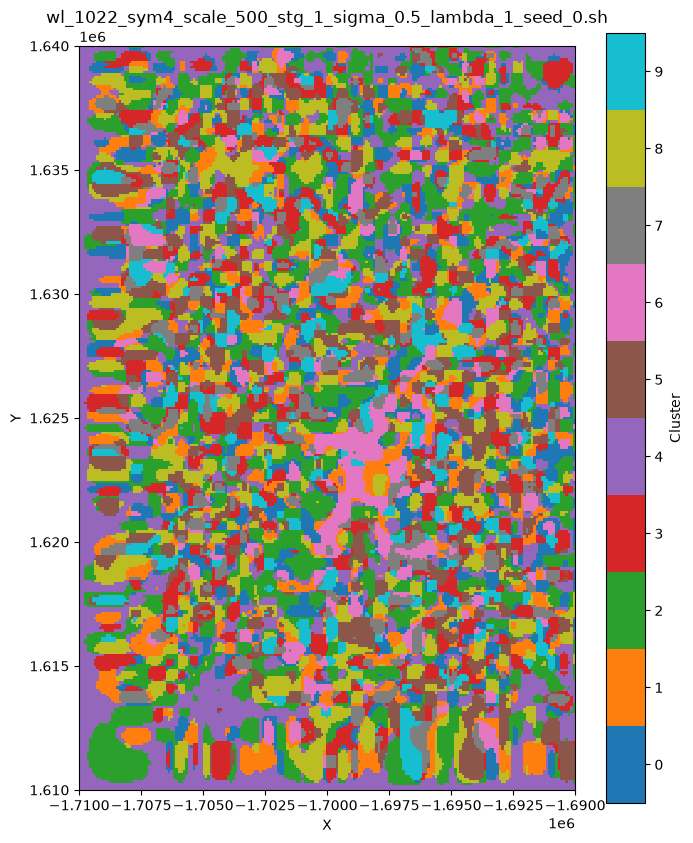

In [34]:
# sh_file = exp_dir / "scripts" / "Place2Vec_2_enc_dec_global_rbf.sh"
sh_file = exp_dir / "scripts" / "wl_1022_db4_scale_1000_stg_1_sigma_0.5_lambda_0.1_seed_0.sh"

num_cluster = 10
output_dir = Path(exp_dir) / "clustering"

with open(sh_file, "r") as f:
    command = f.read()

command = sh_file.read_text(encoding="utf-8")

# 行末の \ による改行を結合
command = command.replace("\\\n", " ")

# コメント・空行を除外し、単語に分割
tokens = shlex.split(command, comments=True)

# trainモジュールの位置を探す
module_name = "spacegraph_codebase.Place2Vec.train"

if module_name not in tokens:
    print(f"SKIP: {sh_file.name}")

start = tokens.index(module_name) + 1
args_list = tokens[start:]

args = parser.parse_args(args_list)


# モデル生成
g_enc_dec = make_enc_dec(args)
g_enc_dec.eval()

coords_np = np.array(coords)
# クラスタリング
with torch.no_grad():
    embeds, cluster_labels = g_spa_enc_embed_clustering(
        g_enc_dec, num_cluster, coords_np
    )

labels = np.asarray(cluster_labels)

# 描画
fig, ax = plt.subplots(figsize=(8, 10))

cmap = plt.get_cmap("tab10", num_cluster)

im = ax.imshow(
    labels,
    origin="lower",
    extent=extent,
    cmap=cmap,
    vmin=-0.5,
    vmax=num_cluster - 0.5,
    interpolation="nearest",
    aspect="equal"
)

fig.colorbar(
    im,
    ax=ax,
    ticks=np.arange(num_cluster),
    label="Cluster"
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title(row["script"])

# 保存
output_path = output_dir / f"{Path(row['script']).stem}.png"

fig.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# メモリ解放
del g_enc_dec, embeds, cluster_labels
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()    

In [19]:
coords_np.ndim

3